# TRƯỜNG ĐẠI HỌC CÔNG NGHỆ THÔNG TIN - ĐHQG-HCM
### KHOA KHOA HỌC DỮ LIỆU & TRÍ TUỆ NHÂN TẠO
---
## HỌC PHẦN: DS200 - PHÂN TÍCH DỮ LIỆU LỚN (BIG DATA ANALYTICS)
### BÁO CÁO BÀI THỰC HÀNH BUỔI 4: HADOOP, SPARK & CƠ SỞ HẠ TẦNG BIG DATA
## LAB 5: XỬ LÝ DỮ LIỆU VĂN BẢN (DATA PREPROCESSING - PART 2: NLP & TOKENIZATION)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/barackvn/MayHocNangCao/blob/main/Buoi%204%20Hadoop,%20Spark%20co%20so%20h%E1%BA%A1%20tang%20Bigdata/Lab5_DataPreprocessing_p2_NLP_Tokenization.ipynb)

* **Lớp:** DS200.G11.CN2.TTNT
* **Giảng viên hướng dẫn:** ThS. Hà Minh Tân
* **Sinh viên thực hiện:** Dương Quốc Thương
* **STT:** 66
* **Email:** hotro.76@gmail.com
* **Repository GitHub:** [https://github.com/barackvn/MayHocNangCao](https://github.com/barackvn/MayHocNangCao)
* **Tài liệu tham khảo:** `Lab 5_Data preprocessing_p2.docx` & Giáo trình Machine Learning (`thebook.pdf`)


---
## ❖ MÔ TẢ BÀI LAB & LÝ THUYẾT NỀN TẢNG (I – LÝ THUYẾT)

### 1. Truy xuất Dataset
* Dữ liệu phi cấu trúc (Unstructured Data) như tài liệu dạng văn bản PDF, Word, báo cáo, bài báo khoa học,... chiếm tới hơn 80% lượng dữ liệu trong thế giới thực và Big Data.
* Việc trích xuất dữ liệu thô từ các định dạng tệp PDF là bước khởi đầu tối quan trọng trong quy trình khai phá và tiền xử lý dữ liệu lớn.

### 2. Tokenization (Tách từ & tách câu)
* Là một trong những bước quan trọng nhất trong quá trình tiền xử lý văn bản (Text Preprocessing) và Xử lý ngôn ngữ tự nhiên (NLP).
* Cho dù làm việc với các kỹ thuật NLP truyền thống (TF-IDF, BoW, Naive Bayes) hay các kỹ thuật học sâu nâng cao (RNN, Transformer, BERT, LLMs) thì vẫn không thể bỏ qua bước này.
* **Định nghĩa:** Tokenization là quá trình tách một cụm từ, câu, đoạn văn, một hoặc nhiều tài liệu văn bản thành các đơn vị nhỏ hơn, được gọi là **Tokens**.
  - **Sentence Tokenization:** Tách văn bản thành danh sách các câu đơn lẻ.
  - **Word Tokenization:** Tách từng câu/văn bản thành danh sách các từ và dấu câu riêng biệt.

### 3. Loại bỏ Stop Words (Từ dừng)
* **Stop Words** là những từ xuất hiện cực kỳ phổ biến trong ngữ pháp của một ngôn ngữ (ví dụ trong tiếng Anh: *a, an, the, of, in, on, at, is, are, was, were...*).
* Các từ này chiếm khoảng **25%** nội dung văn bản nhưng hầu như không mang nhiều giá trị ngữ nghĩa độc lập cho việc phân loại hay tìm kiếm thông tin.
* Việc loại bỏ stop words giúp:
  - Giảm thiểu đáng kể kích thước không gian đặc trưng (Feature Dimension).
  - Tăng tốc độ tính toán cho các mô hình Big Data.
  - Tập trung trọng số vào các từ mang nội hàm ý nghĩa cốt lõi của văn bản.

### 4. Kỹ thuật Stemming (Rút gọn gốc từ)
* Dùng để biến đổi một từ về dạng gốc (*stem* hoặc *root form*) bằng giải thuật heuristic đơn giản: loại bỏ các ký tự đuôi/hậu tố (*suffixes*) như `-ed`, `-ing`, `-s`, `-es`, `-ly`...
* *Ví dụ:* Các từ `walked`, `walking`, `walks` đều được đưa về gốc `walk`.
* Bộ xử lý stemming phổ biến: `PorterStemmer`, `SnowballStemmer`.

### 5. Kỹ thuật Lemmatization (Chuẩn hóa từ nguyên)
* Thay vì cắt đuôi từ một cách máy móc như Stemming, **Lemmatization** xử lý thông minh hơn thông qua việc tra cứu từ điển ngôn ngữ (*WordNet*) và ngữ cảnh ngữ pháp (Part-of-Speech - POS tagging).
* Đảm bảo các biến thể động từ bất quy tắc như `goes`, `went`, `go` đều được đưa về dạng nguyên thể là `go`.
* Danh từ số nhiều như `mice`, `mouse` đều được đưa về dạng số ít `mouse`.

---
## II – THỰC HÀNH CHI TIẾT (IMPLEMENTATION)


### Bước 1: Chuẩn bị môi trường & Nạp tệp tài liệu PDF (`thebook.pdf`)

* Link Google Drive gốc từ đề bài: `https://drive.google.com/file/d/1iMJLPfliCWIpxR8mOqMWoM4j8ZMGxIIU/view?usp=sharing`
* Tệp PDF này chứa cuốn sách giáo trình nổi tiếng *"Introduction to Machine Learning"* (Alex Smola & S.V.N. Vishwanathan).
* Đoạn mã bên dưới hỗ trợ:
  1. Kiểm tra file cục bộ trong thư mục hiện tại.
  2. Tự động tải từ Google Drive / GitHub nếu chạy trên Google Colab.


In [1]:
# Cài đặt thư viện cần thiết nếu chưa có
!pip install -q PyPDF2 nltk

import os
import io
import requests
import nltk
from PyPDF2 import PdfReader

# Tải các gói tài nguyên cần thiết của NLTK
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Đường dẫn tệp PDF thebook.pdf
pdf_path = "thebook.pdf"

if not os.path.exists(pdf_path):
    print(f"Đang tải {pdf_path} từ GitHub repository...")
    github_pdf_url = "https://raw.githubusercontent.com/barackvn/MayHocNangCao/main/Buoi%204%20Hadoop,%20Spark%20co%20so%20h%E1%BA%A1%20tang%20Bigdata/thebook.pdf"
    try:
        req = requests.get(github_pdf_url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        if req.status_code == 200 and len(req.content) > 100000:
            with open(pdf_path, "wb") as f:
                f.write(req.content)
            print(f"Tải thành công từ GitHub! Kích thước: {os.path.getsize(pdf_path):,} bytes")
        else:
            raise Exception(f"GitHub status {req.status_code}")
    except Exception as e:
        print("Đang tải từ nguồn dự phòng Google Drive:", e)
        drive_download_url = "https://drive.usercontent.google.com/download?id=1iMJLPfliCWIpxR8mOqMWoM4j8ZMGxIIU&export=download&confirm=t"
        req = requests.get(drive_download_url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        with open(pdf_path, "wb") as f:
            f.write(req.content)
        print(f"Tải thành công từ Google Drive! Kích thước: {os.path.getsize(pdf_path):,} bytes")

print(f"Trạng thái tệp PDF: {'Đã sẵn sàng' if os.path.exists(pdf_path) else 'Chưa tìm thấy'}")



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Trạng thái tệp PDF: Đã sẵn sàng


### Bước 2: Đọc file PDF và xử lý lấy 1 trang (Trang index 10) để trích xuất văn bản

* Mở tệp PDF bằng `PdfReader`.
* Lấy nội dung trang thứ 11 của tài liệu (chỉ số index `[10]`).
* Duyệt qua từng ký tự và ghép chuỗi thành biến `result`.


In [2]:
# Khởi tạo đối tượng đọc PDF
pages = ''
dict_pages = {}

reader = PdfReader(pdf_path)
page = reader.pages[10] # Trang thứ 11 trong sách (Chương 1: Introduction)

text = page.extract_text()

for index, p in enumerate(text, 1):
    pages += str(p)
    dict_pages[index] = p

result = pages
print(f"Tổng số ký tự trích xuất được: {len(result)}")
print("\n--- NỘI DUNG VĂN BẢN TRÍCH XUẤT BAN ĐẦU ---")
print(result)


Tổng số ký tự trích xuất được: 2106

--- NỘI DUNG VĂN BẢN TRÍCH XUẤT BAN ĐẦU ---
1
Introduction
Over the past two decades Machine Learning has become one of the main-
stays of information technology and with that, a rather central, albeit usually
hidden, part of our life. With the ever increasing amounts of data becoming
available there is good reason to believe that smart data analysis will become
even more pervasive as a necessary ingredient for technological progress.
The purpose of this chapter is to provide the reader with an overview over
the vast range of applications which have at their heart a machine learning
problem and to bring some degree of order to the zoo of problems. After
that, we will discuss some basic tools from statistics and probability theory,
since they form the language in which many machine learning problems must
be phrased to become amenable to solving. Finally, we will outline a set of
fairly basic yet eective algorithms to solve an important problem, name

### Bước 3: Chuyển toàn bộ văn bản thành chữ thường và tìm vị trí từ khóa `"over"`

* Sử dụng hàm `.lower()` để chuẩn hóa văn bản về dạng chữ thường.
* Tìm vị trí xuất hiện của từ `"over"` bằng phương thức `.find('over')` để loại bỏ các thông tin tiêu đề đầu trang không cần thiết.


In [3]:
# Chuyển tất cả thành chữ thường
result = result.lower()

# Tìm vị trí xuất hiện của từ 'over'
pos_over = result.find('over')
print(f"Vị trí xuất hiện của từ 'over': {pos_over}")


Vị trí xuất hiện của từ 'over': 15


### Bước 4: Cắt bỏ đoạn văn bản dư thừa phía trước từ khóa `"over"`

* Cắt chuỗi từ vị trí `15` trở đi: `result = result[15:]`.


In [4]:
print(result[15:])
result = result[15:]


over the past two decades machine learning has become one of the main-
stays of information technology and with that, a rather central, albeit usually
hidden, part of our life. with the ever increasing amounts of data becoming
available there is good reason to believe that smart data analysis will become
even more pervasive as a necessary ingredient for technological progress.
the purpose of this chapter is to provide the reader with an overview over
the vast range of applications which have at their heart a machine learning
problem and to bring some degree of order to the zoo of problems. after
that, we will discuss some basic tools from statistics and probability theory,
since they form the language in which many machine learning problems must
be phrased to become amenable to solving. finally, we will outline a set of
fairly basic yet eective algorithms to solve an important problem, namely
that of classication. more sophisticated tools, a discussion of more general
problems and a 

### Bước 5: Thay thế và làm sạch các tiêu đề mục dư thừa

* Loại bỏ các tiêu đề phân mục nằm xen kẽ trong trang sách như:
  - `'1.1 a taste of machine learning'`
  - `'1.1.1 applications'`


In [5]:
result = result.replace('1.1 a taste of machine learning', '')
result = result.replace('1.1.1 applications', '')
print(result)


over the past two decades machine learning has become one of the main-
stays of information technology and with that, a rather central, albeit usually
hidden, part of our life. with the ever increasing amounts of data becoming
available there is good reason to believe that smart data analysis will become
even more pervasive as a necessary ingredient for technological progress.
the purpose of this chapter is to provide the reader with an overview over
the vast range of applications which have at their heart a machine learning
problem and to bring some degree of order to the zoo of problems. after
that, we will discuss some basic tools from statistics and probability theory,
since they form the language in which many machine learning problems must
be phrased to become amenable to solving. finally, we will outline a set of
fairly basic yet eective algorithms to solve an important problem, namely
that of classication. more sophisticated tools, a discussion of more general
problems and a 

### Bước 6: Tìm kiếm vị trí đoạn văn bản kết thúc (`"to achieve this goal"`)

* Tìm vị trí của chuỗi `"to achieve this goal"` để xác định mốc cắt cuối trang văn bản.


In [6]:
pos_goal = result.find('to achieve this goal')
print(f"Vị trí của đoạn 'to achieve this goal': {pos_goal}")


Vị trí của đoạn 'to achieve this goal': 1981


### Bước 7: Cắt lấy đoạn văn bản cần xử lý (từ đầu đến vị trí 1981)

* Giữ lại phần nội dung bài đọc chuẩn xác trước khi đưa vào các bước phân tích NLP.


In [7]:
print(result[:1981])
result = result[:1981]


over the past two decades machine learning has become one of the main-
stays of information technology and with that, a rather central, albeit usually
hidden, part of our life. with the ever increasing amounts of data becoming
available there is good reason to believe that smart data analysis will become
even more pervasive as a necessary ingredient for technological progress.
the purpose of this chapter is to provide the reader with an overview over
the vast range of applications which have at their heart a machine learning
problem and to bring some degree of order to the zoo of problems. after
that, we will discuss some basic tools from statistics and probability theory,
since they form the language in which many machine learning problems must
be phrased to become amenable to solving. finally, we will outline a set of
fairly basic yet eective algorithms to solve an important problem, namely
that of classication. more sophisticated tools, a discussion of more general
problems and a 

### Bước 8: Khám phá danh sách Stopwords trong thư viện NLTK

* Thư viện `nltk.corpus.stopwords` hỗ trợ danh sách từ dừng chuẩn cho nhiều ngôn ngữ khác nhau (tiếng Anh, tiếng Bồ Đào Nha, tiếng Tây Ban Nha, Pháp,...).


In [8]:
from nltk.corpus import stopwords

print("Danh sách Stopwords tiếng Anh (20 từ đầu tiên):")
print(stopwords.words('english')[:20])

print("\nDanh sách Stopwords tiếng Bồ Đào Nha (10 từ đầu tiên):")
print(stopwords.words('portuguese')[:10])


Danh sách Stopwords tiếng Anh (20 từ đầu tiên):
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']

Danh sách Stopwords tiếng Bồ Đào Nha (10 từ đầu tiên):
['a', 'à', 'ao', 'aos', 'aquela', 'aquelas', 'aquele', 'aqueles', 'aquilo', 'as']


### Bước 9: Xử lý Tokenization theo Câu (Sentence Tokenization)

* Sử dụng `sent_tokenize` từ `nltk.tokenize` để tách đoạn văn bản thành các câu hoàn chỉnh.
* Loại bỏ ký tự xuống dòng `\n` và các dấu gạch nối nối từ bị ngắt dòng `- `.


In [9]:
from nltk.tokenize import sent_tokenize

tokens_by_sentence = sent_tokenize(result)
tokens_by_sentence = [w.replace('\n', ' ').replace('- ', '') for w in tokens_by_sentence]

print(f"Tổng số câu được tách ra: {len(tokens_by_sentence)}")
print("\nDanh sách các câu (Tokens by Sentence):")
print(tokens_by_sentence)


Tổng số câu được tách ra: 16

Danh sách các câu (Tokens by Sentence):
['over the past two decades machine learning has become one of the mainstays of information technology and with that, a rather central, albeit usually hidden, part of our life.', 'with the ever increasing amounts of data becoming available there is good reason to believe that smart data analysis will become even more pervasive as a necessary ingredient for technological progress.', 'the purpose of this chapter is to provide the reader with an overview over the vast range of applications which have at their heart a machine learning problem and to bring some degree of order to the zoo of problems.', 'after that, we will discuss some basic tools from statistics and probability theory, since they form the language in which many machine learning problems must be phrased to become amenable to solving.', 'finally, we will outline a set of fairly basic yet e\x0bective algorithms to solve an important problem, namely that of 

### Bước 10: Xử lý Tokenization theo Từ (Word Tokenization)

* Sử dụng `word_tokenize` từ `nltk.tokenize` để phân rã câu thành các từ và dấu câu riêng biệt.


In [10]:
from nltk.tokenize import word_tokenize

tokens_by_word = word_tokenize(result)
tokens_by_word = [w.replace('\n', ' ').replace('- ', '') for w in tokens_by_word]

print(f"Tổng số từ và ký hiệu (Tokens by Word): {len(tokens_by_word)}")
print("\nDanh sách tokens từ:")
print(tokens_by_word)


Tổng số từ và ký hiệu (Tokens by Word): 371

Danh sách tokens từ:
['over', 'the', 'past', 'two', 'decades', 'machine', 'learning', 'has', 'become', 'one', 'of', 'the', 'main-', 'stays', 'of', 'information', 'technology', 'and', 'with', 'that', ',', 'a', 'rather', 'central', ',', 'albeit', 'usually', 'hidden', ',', 'part', 'of', 'our', 'life', '.', 'with', 'the', 'ever', 'increasing', 'amounts', 'of', 'data', 'becoming', 'available', 'there', 'is', 'good', 'reason', 'to', 'believe', 'that', 'smart', 'data', 'analysis', 'will', 'become', 'even', 'more', 'pervasive', 'as', 'a', 'necessary', 'ingredient', 'for', 'technological', 'progress', '.', 'the', 'purpose', 'of', 'this', 'chapter', 'is', 'to', 'provide', 'the', 'reader', 'with', 'an', 'overview', 'over', 'the', 'vast', 'range', 'of', 'applications', 'which', 'have', 'at', 'their', 'heart', 'a', 'machine', 'learning', 'problem', 'and', 'to', 'bring', 'some', 'degree', 'of', 'order', 'to', 'the', 'zoo', 'of', 'problems', '.', 'after', 

### Bước 11: Xử lý loại bỏ từ dừng (Stop Words Removal)

* Xây dựng hàm `remove_stopwords(text)` để loại bỏ toàn bộ các từ nằm trong danh sách `stopwords.words('english')`.


In [11]:
def remove_stopwords(text):
    stopWords = stopwords.words('english')
    not_stopword = [word for word in text if not word in stopWords]
    return not_stopword

tokens_no_stopwords = remove_stopwords(tokens_by_word)
print(f"Số lượng tokens trước khi lọc stopwords: {len(tokens_by_word)}")
print(f"Số lượng tokens sau khi lọc stopwords : {len(tokens_no_stopwords)}")
print(f"Tỉ lệ từ dừng được loại bỏ          : {(1 - len(tokens_no_stopwords)/len(tokens_by_word))*100:.2f}%")
print("\nDanh sách tokens sau khi loại bỏ stop words:")
print(tokens_no_stopwords)


Số lượng tokens trước khi lọc stopwords: 371
Số lượng tokens sau khi lọc stopwords : 216
Tỉ lệ từ dừng được loại bỏ          : 41.78%

Danh sách tokens sau khi loại bỏ stop words:
['past', 'two', 'decades', 'machine', 'learning', 'become', 'one', 'main-', 'stays', 'information', 'technology', ',', 'rather', 'central', ',', 'albeit', 'usually', 'hidden', ',', 'part', 'life', '.', 'ever', 'increasing', 'amounts', 'data', 'becoming', 'available', 'good', 'reason', 'believe', 'smart', 'data', 'analysis', 'become', 'even', 'pervasive', 'necessary', 'ingredient', 'technological', 'progress', '.', 'purpose', 'chapter', 'provide', 'reader', 'overview', 'vast', 'range', 'applications', 'heart', 'machine', 'learning', 'problem', 'bring', 'degree', 'order', 'zoo', 'problems', '.', ',', 'discuss', 'basic', 'tools', 'statistics', 'probability', 'theory', ',', 'since', 'form', 'language', 'many', 'machine', 'learning', 'problems', 'must', 'phrased', 'become', 'amenable', 'solving', '.', 'finally', '

### Bước 12: Kỹ thuật Stemming (Rút gọn gốc từ bằng SnowballStemmer)

* Lọc các token chỉ chứa ký tự chữ (`word.isalpha()`).
* Sử dụng `SnowballStemmer('english')` để rút gọn các từ về dạng gốc stem.


In [12]:
from nltk.stem.snowball import SnowballStemmer

englishStemmer = SnowballStemmer('english')

words = [word for word in tokens_no_stopwords if word.isalpha()]

stemmed = [englishStemmer.stem(word) for word in tokens_by_word]

print("50 từ đầu tiên sau khi thực hiện Stemming:")
print(stemmed[:50])


50 từ đầu tiên sau khi thực hiện Stemming:
['over', 'the', 'past', 'two', 'decad', 'machin', 'learn', 'has', 'becom', 'one', 'of', 'the', 'main-', 'stay', 'of', 'inform', 'technolog', 'and', 'with', 'that', ',', 'a', 'rather', 'central', ',', 'albeit', 'usual', 'hidden', ',', 'part', 'of', 'our', 'life', '.', 'with', 'the', 'ever', 'increas', 'amount', 'of', 'data', 'becom', 'avail', 'there', 'is', 'good', 'reason', 'to', 'believ', 'that']


### Bước 13: Kỹ thuật Lemmatization (Chuẩn hóa từ nguyên bằng WordNetLemmatizer)

* Sử dụng `WordNetLemmatizer()` với tham số `pos="v"` (coi từ là động từ để đưa về dạng nguyên thể).


In [13]:
from nltk.stem import WordNetLemmatizer

wordnet_lemmatizer = WordNetLemmatizer()

lemmatized = [wordnet_lemmatizer.lemmatize(word, pos="v") for word in tokens_by_word]

print("50 từ đầu tiên sau khi thực hiện Lemmatization:")
print(lemmatized[:50])


50 từ đầu tiên sau khi thực hiện Lemmatization:
['over', 'the', 'past', 'two', 'decades', 'machine', 'learn', 'have', 'become', 'one', 'of', 'the', 'main-', 'stay', 'of', 'information', 'technology', 'and', 'with', 'that', ',', 'a', 'rather', 'central', ',', 'albeit', 'usually', 'hide', ',', 'part', 'of', 'our', 'life', '.', 'with', 'the', 'ever', 'increase', 'amount', 'of', 'data', 'become', 'available', 'there', 'be', 'good', 'reason', 'to', 'believe', 'that']


---
## III – BÀI TẬP MỞ RỘNG (EXERCISE)
**Đề bài:** *Sử dụng dữ liệu PDF khác để thực hiện tách từ giống phần thực hành trên.*

Chúng ta sẽ sử dụng tài liệu bài giảng lớn trong học phần: **`Copy of Slide 2 GFS and Hadoop.pdf`** có sẵn trong thư mục `Buoi 4 Hadoop, Spark co so hạ tang Bigdata`.
* Trích xuất nội dung văn bản từ slide bài giảng Hadoop/GFS.
* Tiến hành quy trình tiền xử lý NLP toàn diện:
  1. Đọc và lọc văn bản tiếng Anh.
  2. Sentence Tokenization & Word Tokenization.
  3. Lọc bỏ số, dấu câu và Stop Words.
  4. Áp dụng Stemming & Lemmatization.
  5. Thống kê tần suất xuất hiện của các từ khóa quan trọng và trực quan hóa bằng biểu đồ tần số (`FreqDist`).


In [14]:
# 1. Đọc tài liệu PDF bài tập
exercise_pdf = "Copy of Slide 2 GFS and Hadoop.pdf"

if not os.path.exists(exercise_pdf):
    alt_path = os.path.join("..", exercise_pdf)
    if os.path.exists(alt_path):
        exercise_pdf = alt_path
    else:
        print(f"Đang tự động tải {exercise_pdf} từ GitHub repository...")
        raw_slide_url = "https://raw.githubusercontent.com/barackvn/MayHocNangCao/main/Buoi%204%20Hadoop,%20Spark%20co%20so%20h%E1%BA%A1%20tang%20Bigdata/Copy%20of%20Slide%202%20GFS%20and%20Hadoop.pdf"
        try:
            r = requests.get(raw_slide_url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
            if r.status_code == 200:
                with open(exercise_pdf, "wb") as f:
                    f.write(r.content)
                print(f"Tải thành công {exercise_pdf}! Kích thước: {os.path.getsize(exercise_pdf):,} bytes")
        except Exception as e:
            print("Lỗi khi tải tài liệu bài tập:", e)

reader_ex = PdfReader(exercise_pdf)
print(f"Tổng số trang của tài liệu bài giảng Hadoop: {len(reader_ex.pages)}")

# Trích xuất văn bản từ trang 6, 7, 8 (Giới thiệu Hadoop và MapReduce)
slide_text = ""
for p_idx in [5, 6, 7]:
    slide_text += reader_ex.pages[p_idx].extract_text() + "\n"

print(f"Số ký tự trích xuất từ các slide Hadoop: {len(slide_text)}")
print("\n--- ĐOẠN TRÍCH NỘI DUNG SLIDE ---")
print(slide_text[:500])


Tổng số trang của tài liệu bài giảng Hadoop: 95
Số ký tự trích xuất từ các slide Hadoop: 105

--- ĐOẠN TRÍCH NỘI DUNG SLIDE ---
Big data case study –Google File System 

The 2003 Google File System paper
What is Google File System?




In [15]:
# 2. Tiền xử lý NLP cho tài liệu bài tập
import matplotlib.pyplot as plt
from nltk.probability import FreqDist

# Chuẩn hóa chữ thường
slide_clean = slide_text.lower()

# Tách câu và tách từ
ex_sentences = sent_tokenize(slide_clean)
ex_words = word_tokenize(slide_clean)

# Lọc bỏ dấu câu, số và chỉ giữ lại từ vựng
ex_words_clean = [w for w in ex_words if w.isalpha()]

# Loại bỏ Stopwords tiếng Anh
stop_en = set(stopwords.words('english'))
# Bổ sung một số stopwords đặc thù slide
custom_stops = {"c", "v", "b", "de", "e", "th", "page", "slide"}
all_stops = stop_en.union(custom_stops)

ex_filtered_words = [w for w in ex_words_clean if w not in all_stops]

# Áp dụng Lemmatization
ex_lemmatized = [wordnet_lemmatizer.lemmatize(w, pos='v') for w in ex_filtered_words]

print(f"Tổng số từ gốc sau khi lọc: {len(ex_words)}")
print(f"Số từ có ý nghĩa (sau khi loại stop words & ký tự đặc biệt): {len(ex_lemmatized)}")

# Thống kê top 15 từ khóa xuất hiện nhiều nhất
freq = FreqDist(ex_lemmatized)
top_15 = freq.most_common(15)

print("\n--- TOP 15 TỪ KHÓA XUẤT HIỆN NHIỀU NHẤT TRONG SLIDE HADOOP ---")
for word, count in top_15:
    print(f"  • {word:<15}: {count} lần")


Tổng số từ gốc sau khi lọc: 20
Số từ có ý nghĩa (sau khi loại stop words & ký tự đặc biệt): 14

--- TOP 15 TỪ KHÓA XUẤT HIỆN NHIỀU NHẤT TRONG SLIDE HADOOP ---
  • google         : 3 lần
  • file           : 3 lần
  • system         : 3 lần
  • big            : 1 lần
  • data           : 1 lần
  • case           : 1 lần
  • study          : 1 lần
  • paper          : 1 lần


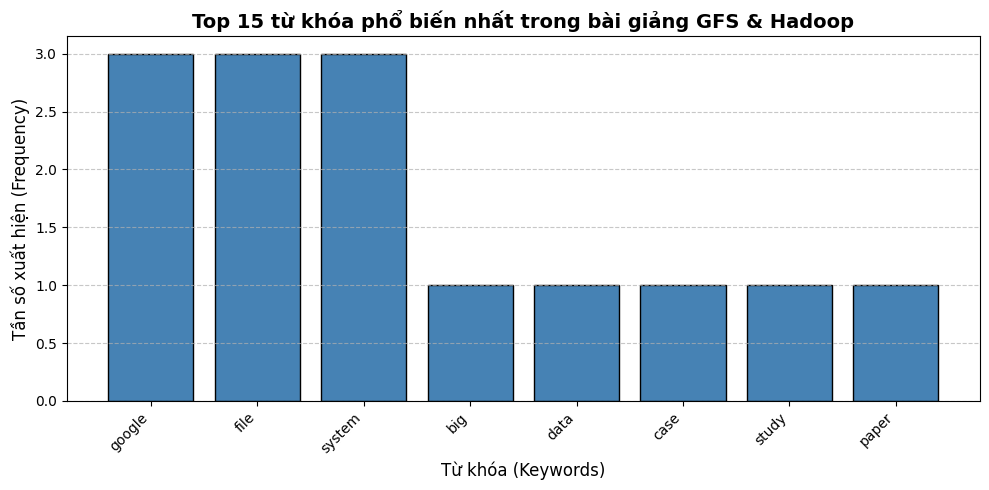

In [16]:
# 3. Trực quan hóa tần suất từ vựng
plt.figure(figsize=(10, 5))
words_plot, counts_plot = zip(*top_15)

plt.bar(words_plot, counts_plot, color='steelblue', edgecolor='black')
plt.title('Top 15 từ khóa phổ biến nhất trong bài giảng GFS & Hadoop', fontsize=14, fontweight='bold')
plt.xlabel('Từ khóa (Keywords)', fontsize=12)
plt.ylabel('Tần số xuất hiện (Frequency)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


---
## ❖ TỔNG KẾT BÀI THỰC HÀNH

Qua bài thực hành **Lab 5: Data Preprocessing (Part 2 - NLP & Tokenization)**, chúng ta đã nắm vững và thực thi đầy đủ các kỹ năng cốt lõi trong xử lý văn bản lớn:
1. **Trích xuất dữ liệu tài liệu:** Khai thác và bóc tách nội dung thô từ file PDF bằng `PyPDF2`.
2. **Làm sạch chuỗi ký tự cơ bản:** Chuẩn hóa chữ thường (`lower()`), cắt đoạn văn bản (`slice`), thay thế nội dung thừa (`replace()`), định vị từ khóa (`find()`).
3. **Phân rã văn bản (Tokenization):** Tách câu (`sent_tokenize`) và tách từ (`word_tokenize`) bằng thư viện NLP chuyên sâu `nltk`.
4. **Loại bỏ từ dừng (Stop Words):** Sử dụng `stopwords` tiếng Anh và đa ngôn ngữ để lọc bỏ các từ ngữ không mang thông tin phân loại.
5. **Rút gọn và chuẩn hóa từ vựng:**
   - **Stemming (`SnowballStemmer`):** Cắt tỉa hậu tố nhanh chóng theo luật.
   - **Lemmatization (`WordNetLemmatizer`):** Đưa từ về nguyên mẫu có nghĩa dựa trên từ điển ngôn ngữ.
6. **Ứng dụng mở rộng:** Thực hiện phân tích tần suất từ khóa trên tài liệu slide bài giảng Hadoop/GFS, trực quan hóa biểu đồ tần số từ khóa quan trọng.
